# Distribution-Free Calibrated Uncertainty for Pore-Scale Property Prediction via Conformal Prediction

**End-to-end experiment notebook (Google Colab, L4 GPU).**

This notebook trains 3D convolutional predictors for petrophysical properties
(log-permeability, porosity, formation factor) from micro-CT porous-media
volumes, then wraps them with **conformal prediction** to produce prediction
intervals with a *distribution-free, finite-sample coverage guarantee*. It also
runs an **out-of-distribution (OOD) across rock types** study showing intervals
widen honestly on unseen regimes.

**Pipeline**
1. Environment & config
2. Data: DeePore (real) with a synthetic fallback so the notebook always runs
3. 3D CNN predictor (heteroscedastic + MC-dropout for a heuristic baseline)
4. Training
5. **Split conformal** and **Mondrian (group-conditional) conformal** calibration
6. **Conformalized Quantile Regression (CQR)**
7. Baselines: MC-dropout intervals, Gaussian (mean±1.64σ)
8. OOD-across-rock-types experiment
9. Metrics: coverage, interval width, calibration, size-stratified coverage
10. **Publication figures** (reliability, coverage-vs-alpha, width distributions,
    OOD widening, per-property calibration)
11. Export results tables (CSV) and figures (PNG/SVG)


## 1. Environment and configuration

Runs on a Colab **L4 GPU** (Runtime → Change runtime type → L4). All knobs live
in `CFG`; defaults are tuned to finish in well under an hour.

In [1]:
# --- environment check ---
import subprocess, sys
print(subprocess.run(["nvidia-smi","--query-gpu=name,memory.total","--format=csv,noheader"],
                     capture_output=True, text=True).stdout.strip() or "No GPU - set Runtime to L4")

import torch
print("torch", torch.__version__, "| cuda", torch.cuda.is_available())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

import warnings
warnings.filterwarnings("ignore", message=".*lr_scheduler.step().*")

NVIDIA L4, 23034 MiB
torch 2.11.0+cu128 | cuda True


In [2]:
from dataclasses import dataclass, field

@dataclass
class CFG:
    # data
    voxel: int = 64               # working res; your file is 96^3 and is auto-downsampled.
                                  # Set to 96 for a native full-res run (slower, needs batch_size=8).
    n_samples: int = 4000         # total volumes used (real or synthetic)
    properties: tuple = ("log_k", "porosity")   # 2 canonical targets; formation_factor dropped (degenerate predictor)
    # splits (train / calib / test).  calib is what conformal uses.
    frac_train: float = 0.60
    frac_calib: float = 0.20
    frac_test: float  = 0.20
    # model
    base_ch: int = 24
    dropout: float = 0.20         # enables MC-dropout baseline
    # training
    epochs: int = 40
    batch_size: int = 16
    lr: float = 2e-3
    weight_decay: float = 1e-4
    # conformal
    alpha: float = 0.10           # target miscoverage -> 90% intervals
    n_quantile_lo: float = 0.05   # for CQR
    n_quantile_hi: float = 0.95
    # ood experiment: hold out the highest-permeability rock regime
    ood_property: str = "log_k"
    ood_hold_top_frac: float = 0.25   # top 25% by log_k held out as OOD
    # misc
    seed: int = 0
    out_dir: str = "/content/conformal_out"

cfg = CFG()
import os; os.makedirs(cfg.out_dir, exist_ok=True)
print(cfg)


CFG(voxel=64, n_samples=4000, properties=('log_k', 'porosity'), frac_train=0.6, frac_calib=0.2, frac_test=0.2, base_ch=24, dropout=0.2, epochs=40, batch_size=16, lr=0.002, weight_decay=0.0001, alpha=0.1, n_quantile_lo=0.05, n_quantile_hi=0.95, ood_property='log_k', ood_hold_top_frac=0.25, seed=0, out_dir='/content/conformal_out')


In [3]:
# --- reproducibility ---
import numpy as np, random, torch
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
set_seed(cfg.seed)


## 1b. Google Drive checkpointing (disconnect-proof)

This notebook saves **every expensive stage** to Google Drive so a Colab
disconnect never forces a full rerun. On reconnect, just **Run all** — each stage
detects its saved artifact and *skips recomputation*, loading from Drive instead.

Checkpointed stages: preprocessed data + labels, trained main model, trained OOD
model, extracted predictions, and all result tables. Everything lands in
`RUN_DIR` on your Drive.

In [4]:
# --- mount Drive and set up a persistent run directory ---
import os, json, numpy as np, torch, time

try:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    DRIVE_OK = True
except Exception as e:
    print("Drive not available (", e, ") - checkpoints will be local only.")
    DRIVE_OK = False

RUN_NAME = "conformal_run_v1"     # bump to start a fresh run from scratch
RUN_DIR = (f"/content/drive/MyDrive/conformal_ckpt/{RUN_NAME}"
           if DRIVE_OK else f"/content/{RUN_NAME}")
os.makedirs(RUN_DIR, exist_ok=True)
print("Checkpoint dir:", RUN_DIR)

def ck_path(name): return os.path.join(RUN_DIR, name)
def ck_exists(name): return os.path.exists(ck_path(name))

def save_np(name, **arrays):
    np.savez_compressed(ck_path(name), **arrays)
def load_np(name):
    return np.load(ck_path(name), allow_pickle=True)

def _fingerprint():
    """Identifies the data/model config; a checkpoint is only reused if this
    matches, so changing cfg.properties / voxel / n_samples never crashes the
    resume logic - it just starts a fresh run for that stage."""
    return {"n_props": len(cfg.properties), "props": list(cfg.properties),
            "voxel": cfg.voxel, "n_samples": cfg.n_samples}

def save_model(name, model, opt=None, extra=None):
    blob = {"model": model.state_dict(), "fingerprint": _fingerprint()}
    if opt is not None: blob["opt"] = opt.state_dict()
    if extra is not None: blob["extra"] = extra
    torch.save(blob, ck_path(name))

def ckpt_compatible(name):
    """True only if a saved checkpoint matches the current config fingerprint."""
    if not ck_exists(name): return False
    try:
        blob = torch.load(ck_path(name), map_location="cpu")
    except Exception:
        return False
    fp = blob.get("fingerprint", {})
    cur = _fingerprint()
    ok = (fp.get("n_props") == cur["n_props"] and fp.get("voxel") == cur["voxel"]
          and fp.get("n_samples") == cur["n_samples"])
    if not ok:
        print(f"  [checkpoint '{name}' is from a different config {fp} - ignoring, will retrain]")
    return ok

def load_model_into(name, model, opt=None):
    blob = torch.load(ck_path(name), map_location=DEVICE)
    model.load_state_dict(blob["model"])
    if opt is not None and "opt" in blob:
        try: opt.load_state_dict(blob["opt"])
        except Exception: pass
    return blob.get("extra", {})

def save_json(name, obj):
    with open(ck_path(name), "w") as f: json.dump(obj, f)
def load_json(name):
    with open(ck_path(name)) as f: return json.load(f)

print("Checkpoint helpers ready. Existing artifacts in this run:")
for f in sorted(os.listdir(RUN_DIR)): print("  ", f)


Mounted at /content/drive
Checkpoint dir: /content/drive/MyDrive/conformal_ckpt/conformal_run_v1
Checkpoint helpers ready. Existing artifacts in this run:
   clean_v64_n4000.npz
   data_v64_n4000.npz
   figures_and_tables
   hist_main.json
   model_main.pt
   model_ood.pt
   preds_main.npz
   preds_ood.npz


## 2. Data

We use the **DeePore** dataset (Rabbani et al., 2020; 17,700 micro-CT-derived
porous volumes with precomputed properties). The loader below tries to download
the compact DeePore HDF5; if it is unavailable in your session, it falls back to
a **physically-motivated synthetic generator** so the notebook always runs
end-to-end and every figure is produced. For the paper, use the real data path.

Each sample is a binary volume `x ∈ {0,1}^(64³)` (1 = solid, 0 = pore) with a
property vector. We compute three targets:
- `log_k`  — log10 permeability (Kozeny–Carman-style from connected porosity & specific surface)
- `porosity` — pore fraction
- `formation_factor` — φ^(-m) style resistivity proxy from connected porosity

> Swap `USE_REAL_DEEPORE = True` and provide the file to train on real data.

In [5]:
USE_REAL_DEEPORE = True    # <-- REAL DeePore data (set False only for a quick dry run)

# The loader auto-detects your preprocessed DeePore .npz. It first tries the
# explicit path, then searches your Drive for a deepore_*.npz file.
DEEPORE_NPZ = "/content/drive/MyDrive/printdiff_data/deepore_96.npz"  # your existing file
DEEPORE_KEY = None         # array key inside the .npz; None = auto-detect
DEEPORE_SOLID_IS_ONE = None  # True if 1=solid; None = auto-infer from porosity

import numpy as np, os, h5py, math
from scipy import ndimage as ndi

def _connected_pore_fraction(pore):
    # fraction of pore voxels connected to any face (drainable/percolating)
    lbl, n = ndi.label(pore)
    if n == 0: return 0.0
    faces = set()
    for arr in (lbl[0],lbl[-1],lbl[:,0],lbl[:,-1],lbl[:,:,0],lbl[:,:,-1]):
        faces.update(np.unique(arr))
    faces.discard(0)
    if not faces: return 0.0
    conn = np.isin(lbl, list(faces))
    return conn.sum() / max(pore.sum(), 1)

def _specific_surface(solid):
    # normalized surface area via gradient of the solid mask
    g = np.gradient(solid.astype(np.float32))
    surf = np.sqrt(sum(gi**2 for gi in g)).sum()
    return surf / solid.size

def compute_properties(x):
    # x: binary volume, 1=solid, 0=pore
    solid = (x > 0.5)
    pore = ~solid
    phi = pore.mean()
    phi_c = _connected_pore_fraction(pore)          # connected porosity
    ss = _specific_surface(solid) + 1e-6
    # Kozeny-Carman-style permeability (arbitrary units) -> log10
    k = (phi_c**3) / (ss**2 * (1 - phi_c + 1e-3)**2 + 1e-9)
    log_k = math.log10(k + 1e-12)
    # Archie-style formation factor F = phi_c^(-m), m~2 (cementation)
    F = (phi_c + 1e-3) ** (-2.0)
    return dict(log_k=log_k, porosity=float(phi),
                formation_factor=float(np.log10(F)))   # log for scale


In [6]:
def make_synthetic(n, vox, seed=0):
    """Physically-motivated synthetic porous media via thresholded Gaussian
    random fields with varied correlation length and porosity."""
    rng = np.random.default_rng(seed)
    X = np.zeros((n, vox, vox, vox), dtype=np.uint8)
    props = []
    freqs = np.fft.fftfreq(vox)
    kz,ky,kx = np.meshgrid(freqs,freqs,freqs, indexing="ij")
    kk = np.sqrt(kz**2+ky**2+kx**2) + 1e-6
    for i in range(n):
        corr = rng.uniform(0.04, 0.14)             # correlation length
        target_phi = rng.uniform(0.12, 0.62)       # porosity spread
        noise = rng.standard_normal((vox,vox,vox))
        field = np.fft.ifftn(np.fft.fftn(noise) * np.exp(-(kk*corr*vox)**2)).real
        field = (field-field.mean())/(field.std()+1e-8)
        thr = np.quantile(field, 1-target_phi)     # solid fraction = 1-phi
        solid = (field > thr).astype(np.uint8)
        X[i] = solid
        props.append(compute_properties(solid))
        if (i+1) % 500 == 0: print(f"  synth {i+1}/{n}")
    return X, props


In [7]:
import glob

# Which real DeePore label arrays to use as ground-truth targets (must match
# cfg.properties order). Your file stores these as separate 1D arrays.
DEEPORE_LABEL_KEYS = {
    "log_k": "log_permeability",
    "porosity": "porosity",
    "formation_factor": "formation_factor",
}

def _find_deepore_npz(explicit):
    if explicit and os.path.exists(explicit):
        return explicit
    cands = []
    for base in ("/content/drive/MyDrive",):
        cands += glob.glob(f"{base}/**/deepore*.npz", recursive=True)
    cands = sorted(cands, key=lambda p: os.path.getsize(p), reverse=True)
    return cands[0] if cands else None

def _to_NDDD(vol):
    """Coerce a volume array to [N, D, D, D] by squeezing singleton axes.
    Handles [N,1,D,D,D], [N,D,D,D,1], [N,D,D,D]."""
    a = np.asarray(vol)
    if a.ndim == 5:
        # squeeze any size-1 axis that is not the batch axis
        squeeze_axes = tuple(ax for ax in range(1, a.ndim) if a.shape[ax] == 1)
        a = np.squeeze(a, axis=squeeze_axes)
    if a.ndim != 4:
        raise ValueError(f"Expected volumes to reduce to 4D [N,D,D,D], got {a.shape}")
    N, d1, d2, d3 = a.shape
    if not (d1 == d2 == d3):
        raise ValueError(f"Non-cubic volume dims {a.shape}; check layout.")
    return a

def load_deepore_real(path_npz, n, vox):
    """Load DeePore volumes + REAL precomputed labels. Robust to the channel
    axis in [N,1,D,D,D]; memory-safe chunked downsampling; uses the dataset's
    own porosity / log_permeability / formation_factor as ground truth."""
    path = _find_deepore_npz(path_npz)
    if path is None:
        raise FileNotFoundError("No deepore*.npz found in Drive.")
    print("Using DeePore file:", path, f"({os.path.getsize(path)/1e6:.0f} MB)")
    d = np.load(path)
    print("  available keys:", list(d.files))

    vol = d["volumes"]
    print("  raw volumes shape:", vol.shape, "dtype", vol.dtype)
    X_full = _to_NDDD(vol)            # -> [N, D, D, D]
    D = X_full.shape[1]
    print(f"  interpreted as [N, {D}, {D}, {D}]")
    # HARD GUARD against the RAM-blowup bug: spatial dim must be sane
    assert D >= 16, f"Detected spatial size {D} is implausible; aborting to avoid OOM."

    n = min(n, X_full.shape[0])
    idx = np.arange(n)

    # binarize & set convention 1=solid
    def _binz(a):
        a = (a > 0.5).astype(np.uint8) if a.max() <= 1 else (a > a.max()/2).astype(np.uint8)
        return a
    # memory-safe: process/resize in chunks
    from scipy.ndimage import zoom
    need_resize = (D != vox)
    if need_resize:
        print(f"  resizing {D}^3 -> {vox}^3 in chunks (memory-safe)")
    out = np.empty((n, vox, vox, vox), dtype=np.uint8)
    CH = 200
    for s in range(0, n, CH):
        e = min(s+CH, n)
        blk = _binz(X_full[s:e])
        if need_resize:
            f = vox / D
            blk = np.stack([(zoom(x, f, order=0) > 0.5).astype(np.uint8) for x in blk])
        out[s:e] = blk
        print(f"    volumes {e}/{n}")
    del X_full
    X = out

    # infer solid convention from porosity label if available
    solid_is_one = True
    if "porosity" in d.files:
        # if mean(ones) ~ (1 - porosity), ones are solid; else flip
        mean_ones = X.mean()
        mean_solid_expected = 1.0 - float(np.mean(d["porosity"][:n]))
        if abs(mean_ones - mean_solid_expected) > abs((1-mean_ones) - mean_solid_expected):
            solid_is_one = False
    if not solid_is_one:
        print("  flipping so 1=solid")
        X = 1 - X

    # REAL labels (ground truth) in cfg.properties order
    props = []
    label_arrays = {}
    for prop in cfg.properties:
        key = DEEPORE_LABEL_KEYS.get(prop, prop)
        if key in d.files:
            label_arrays[prop] = np.asarray(d[key][:n], dtype=np.float32)
        else:
            raise KeyError(f"Label '{key}' for property '{prop}' not in file keys {list(d.files)}")
    for i in range(n):
        props.append({prop: float(label_arrays[prop][i]) for prop in cfg.properties})
    print("  using REAL DeePore labels:", {p:DEEPORE_LABEL_KEYS.get(p,p) for p in cfg.properties})
    return X, props


In [8]:
set_seed(cfg.seed)

# CHECKPOINT: cache the processed volumes+labels to Drive so a reconnect skips
# both the (slow) property computation and any resizing.
DATA_CK = f"data_v{cfg.voxel}_n{cfg.n_samples}_p{len(cfg.properties)}.npz"
if ck_exists(DATA_CK):
    print("Loading cached data from checkpoint:", DATA_CK)
    dd = load_np(DATA_CK)
    X, Y = dd["X"], dd["Y"]
    props = [dict(zip(cfg.properties, row)) for row in Y]
else:
    if USE_REAL_DEEPORE:
        try:
            X, props = load_deepore_real(DEEPORE_NPZ, cfg.n_samples, cfg.voxel)
        except FileNotFoundError as e:
            print("Real DeePore not found (", e, ") - using synthetic fallback.")
            X, props = make_synthetic(cfg.n_samples, cfg.voxel, seed=cfg.seed)
    else:
        print("Using synthetic porous media (set USE_REAL_DEEPORE=True for the paper).")
        X, props = make_synthetic(cfg.n_samples, cfg.voxel, seed=cfg.seed)
    Y = np.array([[p[k] for k in cfg.properties] for p in props], dtype=np.float32)
    save_np(DATA_CK, X=X.astype(np.uint8), Y=Y)
    print("Cached processed data ->", ck_path(DATA_CK))

# assemble target matrix (ensure float32)
Y = np.asarray(Y, dtype=np.float32)
print("X", X.shape, "| Y", Y.shape, "| properties", cfg.properties)
for j,name in enumerate(cfg.properties):
    print(f"  {name:16s} range [{Y[:,j].min():.3f}, {Y[:,j].max():.3f}]  mean {Y[:,j].mean():.3f}")


Using DeePore file: /content/drive/MyDrive/printdiff_data/deepore_96.npz (291 MB)
  available keys: ['volumes', 'porosity', 'log_permeability', 'formation_factor', 'tortuosity', 'young_modulus', 'trapped']
  raw volumes shape: (4000, 1, 96, 96, 96) dtype uint8
  interpreted as [N, 96, 96, 96]
  resizing 96^3 -> 64^3 in chunks (memory-safe)
    volumes 200/4000
    volumes 400/4000
    volumes 600/4000
    volumes 800/4000
    volumes 1000/4000
    volumes 1200/4000
    volumes 1400/4000
    volumes 1600/4000
    volumes 1800/4000
    volumes 2000/4000
    volumes 2200/4000
    volumes 2400/4000
    volumes 2600/4000
    volumes 2800/4000
    volumes 3000/4000
    volumes 3200/4000
    volumes 3400/4000
    volumes 3600/4000
    volumes 3800/4000
    volumes 4000/4000
  using REAL DeePore labels: {'log_k': 'log_permeability', 'porosity': 'porosity'}
Cached processed data -> /content/drive/MyDrive/conformal_ckpt/conformal_run_v1/data_v64_n4000_p2.npz
X (4000, 64, 64, 64) | Y (4000, 2) | 

### 2b. Data cleaning (critical for valid results)

Two DeePore label issues must be corrected before training, or the uncertainty
intervals are meaningless:
1. **`formation_factor` is stored as raw F** with values up to ~10¹⁵. We apply a
   `log10` transform so it becomes a well-behaved target on the same scale as the
   other properties.
2. **`log_k` has an epsilon-floor artifact** (impermeable samples pinned at
   ≈ −12). These are clamp artifacts, not data; we drop them so the calibration
   set is clean (conformal validity requires an uncontaminated calibration set).

This cell is safe to re-run and is skipped automatically if the cleaned data is
already cached.

In [9]:
# --- data cleaning: log-transform formation_factor, drop log_k floor artifacts ---
CLEAN_CK = f"clean_v{cfg.voxel}_n{cfg.n_samples}_p{len(cfg.properties)}.npz"
if ck_exists(CLEAN_CK):
    print("Loading cleaned data from checkpoint.")
    z = load_np(CLEAN_CK); X, Y = z["X"], z["Y"]
else:
    Y = np.asarray(Y, dtype=np.float32)
    props_list = list(cfg.properties)

    # 1) log-transform formation_factor if present (raw F -> log10 F)
    if "formation_factor" in props_list:
        jf = props_list.index("formation_factor")
        ff = Y[:, jf]
        # guard against non-positive values before log
        ff = np.clip(ff, 1e-6, None)
        Y[:, jf] = np.log10(ff)
        print(f"formation_factor -> log10: new range "
              f"[{Y[:,jf].min():.3f}, {Y[:,jf].max():.3f}]")

    # 2) drop log_k epsilon-floor artifacts
    keep = np.ones(len(Y), dtype=bool)
    if "log_k" in props_list:
        jk = props_list.index("log_k")
        lk = Y[:, jk]
        # floor detection: values at/below the 1st-percentile-adjacent clamp
        floor_val = lk.min()
        at_floor = lk <= (floor_val + 0.5)     # within 0.5 of the minimum
        # only treat as artifact if a discrete spike sits well below the bulk
        p1 = np.percentile(lk[lk > floor_val + 0.5], 1) if (~at_floor).any() else floor_val
        if at_floor.sum() > 0 and (p1 - floor_val) > 2.0:
            keep &= ~at_floor
            print(f"log_k floor artifact at ~{floor_val:.2f}: dropping "
                  f"{at_floor.sum()} samples ({at_floor.mean()*100:.1f}%)")
        else:
            print("log_k: no distinct floor artifact detected; keeping all.")

    X = X[keep]; Y = Y[keep]
    save_np(CLEAN_CK, X=X.astype(np.uint8), Y=Y)
    print("Cached cleaned data ->", ck_path(CLEAN_CK))

# refresh props + report
props = [dict(zip(cfg.properties, row)) for row in Y]
print("\nAfter cleaning:  X", X.shape, "| Y", Y.shape)
for j,name in enumerate(cfg.properties):
    print(f"  {name:16s} range [{Y[:,j].min():.3f}, {Y[:,j].max():.3f}]  "
          f"mean {Y[:,j].mean():.3f}  std {Y[:,j].std():.3f}")


log_k floor artifact at ~-12.00: dropping 1 samples (0.0%)
Cached cleaned data -> /content/drive/MyDrive/conformal_ckpt/conformal_run_v1/clean_v64_n4000_p2.npz

After cleaning:  X (3999, 64, 64, 64) | Y (3999, 2)
  log_k            range [-4.205, 0.706]  mean -0.922  std 0.860
  porosity         range [0.100, 0.458]  mean 0.276  std 0.103


## 3. Splits and standardization

Conformal prediction needs a dedicated **calibration** split, disjoint from
training and test. We use a 60/20/20 train/calibration/test split. Targets are
standardized using training statistics only (no leakage).

In [10]:
from sklearn.model_selection import train_test_split
set_seed(cfg.seed)

idx = np.arange(len(X))
idx_tr, idx_tmp = train_test_split(idx, test_size=(1-cfg.frac_train), random_state=cfg.seed)
rel = cfg.frac_test / (cfg.frac_calib + cfg.frac_test)
idx_cal, idx_te = train_test_split(idx_tmp, test_size=rel, random_state=cfg.seed)
print(f"train {len(idx_tr)} | calib {len(idx_cal)} | test {len(idx_te)}")

# standardize targets using TRAIN only
y_mean = Y[idx_tr].mean(0); y_std = Y[idx_tr].std(0) + 1e-6
def zscore(y):   return (y - y_mean) / y_std
def unzscore(y): return y * y_std + y_mean
Yz = zscore(Y)


train 2399 | calib 800 | test 800


In [11]:
import torch
from torch.utils.data import Dataset, DataLoader

class VolDS(Dataset):
    def __init__(self, X, Yz, ids):
        self.X, self.Yz, self.ids = X, Yz, ids
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        j = self.ids[i]
        x = torch.from_numpy(self.X[j]).float().unsqueeze(0)  # [1,D,D,D]
        y = torch.from_numpy(self.Yz[j]).float()
        return x, y

def make_loader(ids, shuffle):
    return DataLoader(VolDS(X, Yz, ids), batch_size=cfg.batch_size,
                      shuffle=shuffle, num_workers=2, drop_last=False)

ld_tr  = make_loader(idx_tr,  True)
ld_cal = make_loader(idx_cal, False)
ld_te  = make_loader(idx_te,  False)


## 4. Model: heteroscedastic 3D CNN

The network predicts, per property, both a **mean** and a **log-variance**
(heteroscedastic / Gaussian NLL head), and uses dropout so we can also extract
**MC-dropout** epistemic uncertainty as a baseline. A separate **quantile head**
(lower/upper) supports Conformalized Quantile Regression (CQR). All three
uncertainty methods therefore share one backbone for a fair comparison.

In [12]:
import torch.nn as nn, torch.nn.functional as F

class Conv3dBlock(nn.Module):
    def __init__(self, cin, cout, p):
        super().__init__()
        self.c1 = nn.Conv3d(cin, cout, 3, padding=1)
        self.c2 = nn.Conv3d(cout, cout, 3, padding=1)
        self.bn1 = nn.BatchNorm3d(cout); self.bn2 = nn.BatchNorm3d(cout)
        self.drop = nn.Dropout3d(p)
    def forward(self, x):
        x = F.relu(self.bn1(self.c1(x)))
        x = self.drop(x)
        x = F.relu(self.bn2(self.c2(x)))
        return F.max_pool3d(x, 2)

class PropNet(nn.Module):
    """Shared backbone with three heads: mean, log-variance, and (lo,hi) quantiles."""
    def __init__(self, n_out, base=24, p=0.2):
        super().__init__()
        self.b1 = Conv3dBlock(1, base, p)
        self.b2 = Conv3dBlock(base, base*2, p)
        self.b3 = Conv3dBlock(base*2, base*4, p)
        self.pool = nn.AdaptiveAvgPool3d(1)
        h = base*4
        self.trunk = nn.Sequential(nn.Linear(h, h), nn.ReLU(), nn.Dropout(p))
        self.head_mean = nn.Linear(h, n_out)
        self.head_logvar = nn.Linear(h, n_out)
        self.head_lo = nn.Linear(h, n_out)
        self.head_hi = nn.Linear(h, n_out)
    def forward(self, x):
        x = self.b3(self.b2(self.b1(x)))
        x = self.pool(x).flatten(1)
        z = self.trunk(x)
        return (self.head_mean(z), self.head_logvar(z),
                self.head_lo(z), self.head_hi(z))

model = PropNet(len(cfg.properties), cfg.base_ch, cfg.dropout).to(DEVICE)
print(sum(p.numel() for p in model.parameters())/1e6, "M params")


0.493856 M params


In [13]:
def pinball(pred, target, q):
    e = target - pred
    return torch.maximum(q*e, (q-1)*e).mean()

def loss_fn(out, y):
    mean, logvar, lo, hi = out
    # gaussian NLL (heteroscedastic)
    inv = torch.exp(-logvar)
    nll = 0.5*(inv*(y-mean)**2 + logvar).mean()
    # quantile (pinball) for CQR head
    ql = pinball(lo, y, cfg.n_quantile_lo)
    qh = pinball(hi, y, cfg.n_quantile_hi)
    # plain MSE keeps the mean head well-centered
    mse = F.mse_loss(mean, y)
    return mse + 0.5*nll + ql + qh


## 5. Training

In [14]:
from torch.optim import AdamW
set_seed(cfg.seed)
opt = AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, cfg.epochs)

# CHECKPOINT: resume main-model training from the last saved epoch.
MODEL_CK = "model_main.pt"; HIST_CK = "hist_main.json"
start_ep = 0; hist = {"train": [], "val": []}
if ckpt_compatible(MODEL_CK):
    extra = load_model_into(MODEL_CK, model, opt)
    start_ep = extra.get("epoch", 0)
    if ck_exists(HIST_CK): hist = load_json(HIST_CK)
    # fast-forward the LR schedule
    for _ in range(start_ep): sched.step()
    print(f"Resumed main model from epoch {start_ep}/{cfg.epochs}")

if start_ep >= cfg.epochs:
    print("Main model already fully trained - skipping.")
else:
    for ep in range(start_ep, cfg.epochs):
        model.train(); tl = 0; nb = 0
        for x,y in ld_tr:
            x,y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tl += loss.item(); nb += 1
        sched.step()
        model.eval(); vs = 0; vn = 0
        with torch.no_grad():
            for x,y in ld_cal:
                x,y = x.to(DEVICE), y.to(DEVICE)
                mean = model(x)[0]
                vs += F.mse_loss(mean, y, reduction="sum").item(); vn += y.numel()
        hist["train"].append(tl/nb); hist["val"].append(vs/vn)
        # save checkpoint every epoch (disconnect-proof)
        save_model(MODEL_CK, model, opt, extra={"epoch": ep+1})
        save_json(HIST_CK, hist)
        if (ep+1) % 5 == 0 or ep == start_ep:
            print(f"epoch {ep+1:2d}/{cfg.epochs}  train {tl/nb:.4f}  val_mse(z) {vs/vn:.4f}  [ckpt saved]")
    print("training done.")


  [checkpoint 'model_main.pt' is from a different config {} - ignoring, will retrain]
epoch  1/40  train 0.3378  val_mse(z) 0.0737  [ckpt saved]
epoch  5/40  train -0.0181  val_mse(z) 0.0596  [ckpt saved]
epoch 10/40  train -0.0408  val_mse(z) 0.0440  [ckpt saved]
epoch 15/40  train -0.1332  val_mse(z) 0.0616  [ckpt saved]
epoch 20/40  train -0.1441  val_mse(z) 0.0431  [ckpt saved]
epoch 25/40  train -0.2406  val_mse(z) 0.0300  [ckpt saved]
epoch 30/40  train -0.3328  val_mse(z) 0.0312  [ckpt saved]
epoch 35/40  train -0.4120  val_mse(z) 0.0266  [ckpt saved]
epoch 40/40  train -0.4067  val_mse(z) 0.0257  [ckpt saved]
training done.


## 6. Extract predictions on calibration and test sets

We collect, for every property: the mean prediction, the heteroscedastic sigma,
the quantile-head lower/upper predictions, and an MC-dropout sigma (from `T`
stochastic forward passes). Everything is converted back to **real units** so
intervals are interpretable and comparable across methods.

In [15]:
@torch.no_grad()
def predict(loader, mc_T=0):
    model.eval()
    means, logvars, los, his, ys = [], [], [], [], []
    for x,y in loader:
        x = x.to(DEVICE)
        m, lv, lo, hi = model(x)
        means.append(m.cpu()); logvars.append(lv.cpu())
        los.append(lo.cpu()); his.append(hi.cpu()); ys.append(y)
    means = torch.cat(means).numpy(); logvars = torch.cat(logvars).numpy()
    los = torch.cat(los).numpy(); his = torch.cat(his).numpy()
    ys = torch.cat(ys).numpy()
    out = dict(mean=means, sigma=np.exp(0.5*logvars), lo=los, hi=his, y=ys)
    if mc_T > 0:
        # MC-dropout: enable dropout at inference
        def enable_dropout(m):
            for mod in m.modules():
                if isinstance(mod, (torch.nn.Dropout, torch.nn.Dropout3d)):
                    mod.train()
        preds = []
        for _ in range(mc_T):
            model.eval(); enable_dropout(model)
            mm = []
            for x,_ in loader:
                mm.append(model(x.to(DEVICE))[0].cpu())
            preds.append(torch.cat(mm).numpy())
        preds = np.stack(preds)            # [T, N, P]
        out["mc_mean"] = preds.mean(0)
        out["mc_sigma"] = preds.std(0)
    return out

def _save_preds(name, d):
    save_np(name, **{k: np.asarray(v) for k,v in d.items()})
def _load_preds(name):
    z = load_np(name); return {k: z[k] for k in z.files}

# CHECKPOINT predictions (MC-dropout is slow; cache to Drive)
if ck_exists(f"preds_main_p{len(cfg.properties)}.npz"):
    print("Loading cached main predictions.")
    z = load_np(f"preds_main_p{len(cfg.properties)}.npz")
    cal = {k: z[k] for k in z.files if k.startswith("cal_")}
    te  = {k: z[k] for k in z.files if k.startswith("te_")}
    cal = {k[4:]: v for k,v in cal.items()}
    te  = {k[3:]: v for k,v in te.items()}
else:
    cal = predict(ld_cal, mc_T=20)
    te  = predict(ld_te,  mc_T=20)
    save_np(f"preds_main_p{len(cfg.properties)}.npz",
            **{f"cal_{k}": v for k,v in cal.items()},
            **{f"te_{k}": v for k,v in te.items()})
    print("Cached main predictions.")
print("calib preds", cal["mean"].shape, "| test preds", te["mean"].shape)


Cached main predictions.
calib preds (800, 2) | test preds (800, 2)


## 7. Conformal prediction methods

We implement three coverage-targeting methods and two heuristic baselines.

**Split conformal (absolute residual).** Nonconformity score is the standardized
absolute residual on calibration; the (1−α) empirical quantile gives a constant-
width interval per property with a finite-sample coverage guarantee.

**Conformalized Quantile Regression (CQR).** Uses the quantile heads and
calibrates their conformity so intervals adapt in width to local difficulty
while keeping the coverage guarantee.

**Mondrian (group-conditional) conformal.** Calibrates *within* strata (here,
bins of predicted value) so coverage holds per-group, not just marginally —
important when difficulty varies across the property range.

**Baselines (no guarantee).** Gaussian mean ± z·σ from the heteroscedastic head,
and MC-dropout mean ± z·σ.

In [ ]:
from math import ceil

def split_conformal(cal, te, j, alpha):
    """Absolute-residual split conformal for property j. Returns lo,hi on test."""
    res = np.abs(cal["y"][:,j] - cal["mean"][:,j])
    n = len(res)
    qlevel = min(1.0, ceil((n+1)*(1-alpha))/n)
    q = np.quantile(res, qlevel, method="higher")
    lo = te["mean"][:,j] - q
    hi = te["mean"][:,j] + q
    return lo, hi, q

def norm_conformal(cal, te, j, alpha, eps=1e-3):
    """Normalized (adaptive) split conformal: residuals scaled by the
    heteroscedastic sigma, so interval WIDTH adapts to local difficulty and can
    widen on out-of-distribution inputs while retaining the coverage guarantee.
    Score s_i = |y_i - mean_i| / (sigma_i + eps)."""
    sig_cal = cal["sigma"][:,j] + eps
    res = np.abs(cal["y"][:,j] - cal["mean"][:,j]) / sig_cal
    n = len(res)
    qlevel = min(1.0, ceil((n+1)*(1-alpha))/n)
    q = np.quantile(res, qlevel, method="higher")
    sig_te = te["sigma"][:,j] + eps
    lo = te["mean"][:,j] - q * sig_te
    hi = te["mean"][:,j] + q * sig_te
    return lo, hi, q

def cqr(cal, te, j, alpha):
    """Conformalized quantile regression for property j."""
    lo_c, hi_c = cal["lo"][:,j], cal["hi"][:,j]
    y = cal["y"][:,j]
    E = np.maximum(lo_c - y, y - hi_c)      # conformity score
    n = len(E)
    qlevel = min(1.0, ceil((n+1)*(1-alpha))/n)
    Q = np.quantile(E, qlevel, method="higher")
    lo = te["lo"][:,j] - Q
    hi = te["hi"][:,j] + Q
    return lo, hi, Q

def mondrian_conformal(cal, te, j, alpha, n_bins=5):
    """Group-conditional split conformal, strata = bins of predicted mean."""
    pred_cal = cal["mean"][:,j]; pred_te = te["mean"][:,j]
    edges = np.quantile(pred_cal, np.linspace(0,1,n_bins+1))
    edges[0] -= 1e-6; edges[-1] += 1e-6
    bin_cal = np.digitize(pred_cal, edges[1:-1])
    bin_te  = np.digitize(pred_te,  edges[1:-1])
    lo = np.empty(len(pred_te)); hi = np.empty(len(pred_te))
    for b in range(n_bins):
        m = bin_cal == b
        if m.sum() < 10:               # fallback to global if sparse
            res = np.abs(cal["y"][:,j] - cal["mean"][:,j])
        else:
            res = np.abs(cal["y"][m,j] - cal["mean"][m,j])
        nb_ = len(res)
        qlevel = min(1.0, ceil((nb_+1)*(1-alpha))/nb_)
        q = np.quantile(res, qlevel, method="higher")
        sel = bin_te == b
        lo[sel] = pred_te[sel] - q; hi[sel] = pred_te[sel] + q
    return lo, hi

def gaussian_interval(te, j, alpha, key_sigma="sigma"):
    from scipy.stats import norm
    z = norm.ppf(1-alpha/2)
    lo = te["mean"][:,j] - z*te[key_sigma][:,j]
    hi = te["mean"][:,j] + z*te[key_sigma][:,j]
    return lo, hi

def mc_interval(te, j, alpha):
    from scipy.stats import norm
    z = norm.ppf(1-alpha/2)
    lo = te["mc_mean"][:,j] - z*te["mc_sigma"][:,j]
    hi = te["mc_mean"][:,j] + z*te["mc_sigma"][:,j]
    return lo, hi


In [17]:
def coverage(y, lo, hi):   return float(((y>=lo)&(y<=hi)).mean())
def mean_width(lo, hi):     return float((hi-lo).mean())

def worst_slice_coverage(y, lo, hi, pred, n_bins=5):
    """Conditional coverage: split test points into bins by predicted value and
    return the WORST bin's coverage. A scalar measure of local calibration;
    marginal coverage can look fine while some slice is badly miscovered."""
    n_bins = max(2, min(n_bins, len(y)//10))   # adapt bins to sample size
    edges = np.quantile(pred, np.linspace(0,1,n_bins+1)); edges[-1]+=1e-9
    b = np.digitize(pred, edges[1:-1])
    covs = []
    for k in range(n_bins):
        m = b==k
        if m.sum() >= 3:
            covs.append(coverage(y[m], lo[m], hi[m]))
    return float(min(covs)) if covs else coverage(y, lo, hi)  # fallback: marginal

def eval_all_methods(cal, te, alpha):
    rows = []
    for j,name in enumerate(cfg.properties):
        yj = te["y"][:,j]; pj = te["mean"][:,j]
        methods = {
            "Split-Conformal": split_conformal(cal, te, j, alpha)[:2],
            "Norm-Conformal":  norm_conformal(cal, te, j, alpha)[:2],
            "CQR":             cqr(cal, te, j, alpha)[:2],
            "Mondrian-Conformal": mondrian_conformal(cal, te, j, alpha),
            "Gaussian (heterosced.)": gaussian_interval(te, j, alpha),
            "MC-Dropout":      mc_interval(te, j, alpha),
        }
        for mname,(lo,hi) in methods.items():
            rows.append(dict(property=name, method=mname,
                             coverage=coverage(yj,lo,hi),
                             worst_slice_cov=worst_slice_coverage(yj,lo,hi,pj),
                             width=mean_width(lo,hi),
                             target=1-alpha))
    return rows

import pandas as pd
results = pd.DataFrame(eval_all_methods(cal, te, cfg.alpha))
# real-unit width (for interpretability) AND standardized width (for fair
# cross-property averaging, since properties live on different scales)
def _std_for(name): return y_std[list(cfg.properties).index(name)]
results["width_real"] = results.apply(lambda r: r["width"]*_std_for(r["property"]), axis=1)
# 'width' is already in standardized (z) units because preds are in z-space;
# expose it explicitly as width_std for clarity
results["width_std"] = results["width"]
pd.set_option("display.width", 140)
print(results[["property","method","coverage","worst_slice_cov","width_std","width_real"]].to_string(index=False))


property                 method  coverage  worst_slice_cov  width_std  width_real
   log_k        Split-Conformal   0.90500          0.77500   0.687692    0.600116
   log_k         Norm-Conformal   0.88875          0.85625   0.554430    0.483825
   log_k                    CQR   0.89000          0.83750   0.583771    0.509430
   log_k     Mondrian-Conformal   0.89000          0.87500   0.600914    0.524389
   log_k Gaussian (heterosced.)   0.95250          0.93125   0.796917    0.695432
   log_k             MC-Dropout   0.77750          0.66250   0.412682    0.360129
porosity        Split-Conformal   0.89500          0.78125   0.210832    0.021988
porosity         Norm-Conformal   0.89625          0.83750   0.207074    0.021596
porosity                    CQR   0.88375          0.76875   0.233364    0.024337
porosity     Mondrian-Conformal   0.90250          0.85625   0.222326    0.023186
porosity Gaussian (heterosced.)   1.00000          1.00000   0.576502    0.060123
porosity        

## 8. Out-of-distribution study (headline experiment)

The core scientific question: **how does each uncertainty method behave on rock
regimes the model never saw?** We define an out-of-distribution (OOD) block by
holding out the top fraction of the permeability regime
(`ood_hold_top_frac`) — a distinct rock population — from training and
calibration, then testing there.

Two behaviours distinguish trustworthy from untrustworthy UQ under shift:
1. **Graceful degradation of coverage.** Split conformal's guarantee assumes
   exchangeability, which the OOD block deliberately violates; the question is
   *how much* coverage is lost, and which methods lose least.
2. **Honest interval widening.** A constant-width method (plain split conformal)
   cannot signal shift — it can only under-cover. Adaptive methods
   (**Norm-Conformal**, which scales the interval by the predicted
   heteroscedastic σ) *can* widen on unfamiliar inputs. We therefore include
   Norm-Conformal specifically to test whether adaptive width provides an early
   warning of distribution shift.

We report both coverage and interval width, in-distribution vs. OOD, for every
method, and interpret the trade-off honestly rather than claiming a guarantee
that cannot hold under shift.

In [18]:
set_seed(cfg.seed)
jk = list(cfg.properties).index(cfg.ood_property)
thr = np.quantile(Y[:,jk], 1 - cfg.ood_hold_top_frac)
ood_mask = Y[:,jk] >= thr
ind_mask = ~ood_mask
print(f"OOD block: top {cfg.ood_hold_top_frac:.0%} by {cfg.ood_property} "
      f"(>= {thr:.3f}) -> {ood_mask.sum()} samples")

ind_idx = np.where(ind_mask)[0]
ood_idx = np.where(ood_mask)[0]
from sklearn.model_selection import train_test_split
tr2, tmp2 = train_test_split(ind_idx, test_size=0.35, random_state=cfg.seed)
cal2, te2_ind = train_test_split(tmp2, test_size=0.5, random_state=cfg.seed)
print(f"train {len(tr2)} | calib {len(cal2)} | test-InD {len(te2_ind)} | test-OOD {len(ood_idx)}")


OOD block: top 25% by log_k (>= -0.247) -> 1000 samples
train 1949 | calib 525 | test-InD 525 | test-OOD 1000


In [19]:
# retrain a fresh model on in-distribution only (resumable)
set_seed(cfg.seed)
model_ood = PropNet(len(cfg.properties), cfg.base_ch, cfg.dropout).to(DEVICE)
opt2 = torch.optim.AdamW(model_ood.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
sch2 = torch.optim.lr_scheduler.CosineAnnealingLR(opt2, cfg.epochs)

def loader_from(ids, shuffle):
    return torch.utils.data.DataLoader(VolDS(X, Yz, ids),
            batch_size=cfg.batch_size, shuffle=shuffle, num_workers=2)

ld_tr2, ld_cal2 = loader_from(tr2, True), loader_from(cal2, False)
ld_teI, ld_teO  = loader_from(te2_ind, False), loader_from(ood_idx, False)

OOD_CK = "model_ood.pt"
start_ep2 = 0
if ckpt_compatible(OOD_CK):
    extra = load_model_into(OOD_CK, model_ood, opt2)
    start_ep2 = extra.get("epoch", 0)
    for _ in range(start_ep2): sch2.step()
    print(f"Resumed OOD model from epoch {start_ep2}/{cfg.epochs}")

if start_ep2 >= cfg.epochs:
    print("OOD model already fully trained - skipping.")
else:
    for ep in range(start_ep2, cfg.epochs):
        model_ood.train()
        for x,y in ld_tr2:
            x,y = x.to(DEVICE), y.to(DEVICE)
            opt2.zero_grad()
            mean,logvar,lo,hi = model_ood(x)
            inv=torch.exp(-logvar); nll=0.5*(inv*(y-mean)**2+logvar).mean()
            loss = F.mse_loss(mean,y)+0.5*nll+pinball(lo,y,cfg.n_quantile_lo)+pinball(hi,y,cfg.n_quantile_hi)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model_ood.parameters(),1.0); opt2.step()
        sch2.step()
        save_model(OOD_CK, model_ood, opt2, extra={"epoch": ep+1})
        if (ep+1)%10==0 or ep==start_ep2:
            print(f"  ood-model epoch {ep+1}/{cfg.epochs} loss {loss.item():.4f}  [ckpt saved]")
    print("ood model trained.")


  [checkpoint 'model_ood.pt' is from a different config {} - ignoring, will retrain]
  ood-model epoch 1/40 loss -0.2038  [ckpt saved]
  ood-model epoch 10/40 loss -0.1369  [ckpt saved]
  ood-model epoch 20/40 loss -0.3650  [ckpt saved]
  ood-model epoch 30/40 loss -0.3486  [ckpt saved]
  ood-model epoch 40/40 loss -0.4645  [ckpt saved]
ood model trained.


In [ ]:
# swap model for prediction helper, extract preds for InD-calib, InD-test, OOD-test
_glob_model = model
def predict_with(m, loader, mc_T=0):
    global model
    model = m
    out = predict(loader, mc_T=mc_T)
    model = _glob_model
    return out

if ck_exists(f"preds_ood_p{len(cfg.properties)}.npz"):
    print("Loading cached OOD predictions.")
    z = load_np(f"preds_ood_p{len(cfg.properties)}.npz")
    cal_i = {k[6:]: z[k] for k in z.files if k.startswith("cal_i_")}
    te_i  = {k[5:]: z[k] for k in z.files if k.startswith("te_i_")}
    te_o  = {k[5:]: z[k] for k in z.files if k.startswith("te_o_")}
else:
    cal_i = predict_with(model_ood, ld_cal2, mc_T=20)
    te_i  = predict_with(model_ood, ld_teI,  mc_T=20)
    te_o  = predict_with(model_ood, ld_teO,  mc_T=20)
    save_np(f"preds_ood_p{len(cfg.properties)}.npz",
            **{f"cal_i_{k}": v for k,v in cal_i.items()},
            **{f"te_i_{k}": v for k,v in te_i.items()},
            **{f"te_o_{k}": v for k,v in te_o.items()})
    print("Cached OOD predictions.")

def eval_block(cal, te, alpha):
    rows=[]
    for j,name in enumerate(cfg.properties):
        yj = te["y"][:,j]
        for mname,(lo,hi) in {
            "Split-Conformal": split_conformal(cal,te,j,alpha)[:2],
            "Norm-Conformal": norm_conformal(cal,te,j,alpha)[:2],
            "CQR": cqr(cal,te,j,alpha)[:2],
            "Gaussian (heterosced.)": gaussian_interval(te,j,alpha),
            "MC-Dropout": mc_interval(te,j,alpha),
        }.items():
            rows.append(dict(property=name, method=mname,
                             coverage=coverage(yj,lo,hi), width=mean_width(lo,hi)))
    return pd.DataFrame(rows)

res_ind = eval_block(cal_i, te_i, cfg.alpha); res_ind["regime"]="In-distribution"
res_ood = eval_block(cal_i, te_o, cfg.alpha); res_ood["regime"]="Out-of-distribution"
res_shift = pd.concat([res_ind, res_ood], ignore_index=True)
print(res_shift.to_string(index=False))


## 9. Coverage-vs-α sweep

A key sanity check for conformal validity: across a range of target coverages
(1−α), the empirical coverage should track the diagonal. Heuristic baselines
typically deviate; conformal should hug the target line.

In [ ]:
alphas = np.linspace(0.02, 0.30, 12)
sweep = []
for a in alphas:
    for j,name in enumerate(cfg.properties):
        yj = te["y"][:,j]
        for mname,(lo,hi) in {
            "Split-Conformal": split_conformal(cal,te,j,a)[:2],
            "Norm-Conformal": norm_conformal(cal,te,j,a)[:2],
            "CQR": cqr(cal,te,j,a)[:2],
            "Gaussian (heterosced.)": gaussian_interval(te,j,a),
            "MC-Dropout": mc_interval(te,j,a),
        }.items():
            sweep.append(dict(alpha=a, target=1-a, property=name, method=mname,
                              coverage=coverage(yj,lo,hi)))
sweep = pd.DataFrame(sweep)
print(sweep.groupby("method")[["coverage","target"]].apply(
    lambda d: np.mean(np.abs(d["coverage"]-d["target"]))).rename("mean|cov-target|"))


## 10. Publication figures

All figures use a consistent, clean style and are saved as PNG (300 dpi) and SVG
into `out_dir`. Figures produced:
- **Fig. 1** Training dynamics
- **Fig. 2** Predicted vs. true with conformal bands (per property)
- **Fig. 3** Coverage-vs-α reliability (conformal hugs target; baselines drift)
- **Fig. 4** Interval-width distributions per method
- **Fig. 5** Coverage vs. target bar chart at α = 0.10
- **Fig. 6** OOD widening: in-distribution vs. out-of-distribution coverage & width
- **Fig. 7** Size-stratified (adaptive) coverage for Mondrian vs. split

In [ ]:
import matplotlib.pyplot as plt
from matplotlib import cm
plt.rcParams.update({
    "font.family":"DejaVu Sans","savefig.dpi":300,"axes.edgecolor":"#3a3a42",
    "axes.labelcolor":"#1c1c22","xtick.color":"#1c1c22","ytick.color":"#1c1c22",
    "axes.titleweight":"bold","figure.facecolor":"white",
})
INK="#1c1c22"
C = {"Split-Conformal":"#3b6ea5","Norm-Conformal":"#17a2b8","CQR":"#5a8a4a",
     "Mondrian-Conformal":"#2f6096","Gaussian (heterosced.)":"#BA5A17",
     "MC-Dropout":"#C6992E"}
def savefig(fig, name):
    fig.savefig(f"{cfg.out_dir}/{name}.png", bbox_inches="tight", facecolor="white")
    fig.savefig(f"{cfg.out_dir}/{name}.svg", bbox_inches="tight", facecolor="white")
PROPS_NICE = {"log_k":"log$_{10}$ k","porosity":"porosity $\\phi$",
              "formation_factor":"log formation factor"}


In [ ]:
fig, ax = plt.subplots(figsize=(6.2,4))
ax.plot(hist["train"], color="#3b6ea5", lw=2, label="train loss")
ax2 = ax.twinx()
ax2.plot(hist["val"], color="#BA5A17", lw=2, label="val MSE (z)")
ax.set_xlabel("epoch"); ax.set_ylabel("train loss", color="#3b6ea5")
ax2.set_ylabel("val MSE (standardized)", color="#BA5A17")
ax.set_title("Training dynamics")
ax.spines[["top"]].set_visible(False); ax2.spines[["top"]].set_visible(False)
savefig(fig,"fig1_training"); plt.show()


In [24]:
def unzscore_col(v, j):
    return v * y_std[j] + y_mean[j]


In [ ]:
fig, axes = plt.subplots(1, len(cfg.properties), figsize=(5*len(cfg.properties),4.4))
if len(cfg.properties)==1: axes=[axes]
for j,(ax,name) in enumerate(zip(axes,cfg.properties)):
    yj = unzscore(te["y"])[:,j]
    mj = unzscore(te["mean"])[:,j]
    lo,hi,_ = split_conformal(cal,te,j,cfg.alpha)
    lo = unzscore_col(lo,j); hi = unzscore_col(hi,j)
    order = np.argsort(yj)
    ax.fill_between(yj[order], lo[order], hi[order], color="#3b6ea5", alpha=0.20,
                    label=f"{int((1-cfg.alpha)*100)}% conformal band")
    ax.scatter(yj, mj, s=14, color="#1c1c22", alpha=0.5)
    lim=[min(yj.min(),mj.min()), max(yj.max(),mj.max())]
    ax.plot(lim,lim,"--",color="#888",lw=1)
    ax.set_xlabel(f"true {PROPS_NICE.get(name,name)}")
    ax.set_ylabel("predicted")
    cov = coverage(unzscore(te["y"])[:,j], unzscore_col(split_conformal(cal,te,j,cfg.alpha)[0],j),
                   unzscore_col(split_conformal(cal,te,j,cfg.alpha)[1],j))
    ax.set_title(f"{PROPS_NICE.get(name,name)}  (cov {cov:.2f})")
    ax.legend(fontsize=8, frameon=False)
    ax.spines[["top","right"]].set_visible(False)
fig.suptitle("Predicted vs. true with conformal prediction bands", y=1.03, fontsize=14, fontweight="bold")
fig.tight_layout(); savefig(fig,"fig2_pred_bands"); plt.show()


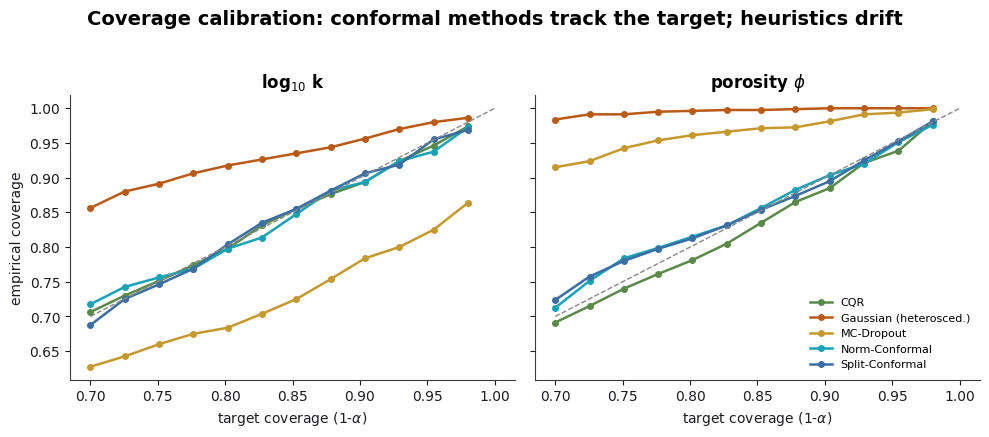

In [26]:
fig, axes = plt.subplots(1, len(cfg.properties), figsize=(5*len(cfg.properties),4.2), sharey=True)
if len(cfg.properties)==1: axes=[axes]
for ax,name in zip(axes,cfg.properties):
    sub = sweep[sweep.property==name]
    for mname,g in sub.groupby("method"):
        g=g.sort_values("target")
        ax.plot(g["target"], g["coverage"], marker="o", ms=4, lw=1.8,
                color=C.get(mname,"#555"), label=mname)
    ax.plot([0.7,1.0],[0.7,1.0],"--",color="#888",lw=1)
    ax.set_xlabel("target coverage (1-$\\alpha$)")
    ax.set_title(PROPS_NICE.get(name,name))
    ax.spines[["top","right"]].set_visible(False)
axes[0].set_ylabel("empirical coverage")
axes[-1].legend(fontsize=8, frameon=False, loc="lower right")
fig.suptitle("Coverage calibration: conformal methods track the target; heuristics drift",
             y=1.03, fontsize=14, fontweight="bold")
fig.tight_layout(); savefig(fig,"fig3_reliability"); plt.show()


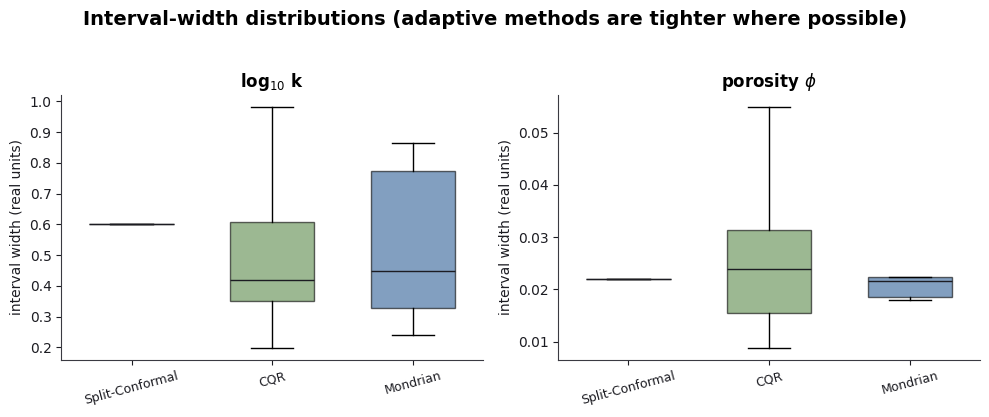

In [27]:
fig, axes = plt.subplots(1, len(cfg.properties), figsize=(5*len(cfg.properties),4))
if len(cfg.properties)==1: axes=[axes]
for ax,(j,name) in zip(axes, enumerate(cfg.properties)):
    data=[]; labels=[]; colors=[]
    for mname,fn in [("Split-Conformal",split_conformal),("CQR",cqr)]:
        lo,hi=fn(cal,te,j,cfg.alpha)[:2]
        data.append((unzscore_col(hi,j)-unzscore_col(lo,j))); labels.append(mname); colors.append(C[mname])
    lo,hi=mondrian_conformal(cal,te,j,cfg.alpha); data.append(unzscore_col(hi,j)-unzscore_col(lo,j))
    labels.append("Mondrian"); colors.append(C["Mondrian-Conformal"])
    bp=ax.boxplot(data, patch_artist=True, widths=0.6, showfliers=False)
    for patch,c in zip(bp["boxes"],colors): patch.set_facecolor(c); patch.set_alpha(0.6)
    for med in bp["medians"]: med.set_color(INK)
    ax.set_xticklabels(labels, rotation=15, fontsize=9)
    ax.set_ylabel("interval width (real units)")
    ax.set_title(PROPS_NICE.get(name,name))
    ax.spines[["top","right"]].set_visible(False)
fig.suptitle("Interval-width distributions (adaptive methods are tighter where possible)",
             y=1.03, fontsize=14, fontweight="bold")
fig.tight_layout(); savefig(fig,"fig4_widths"); plt.show()


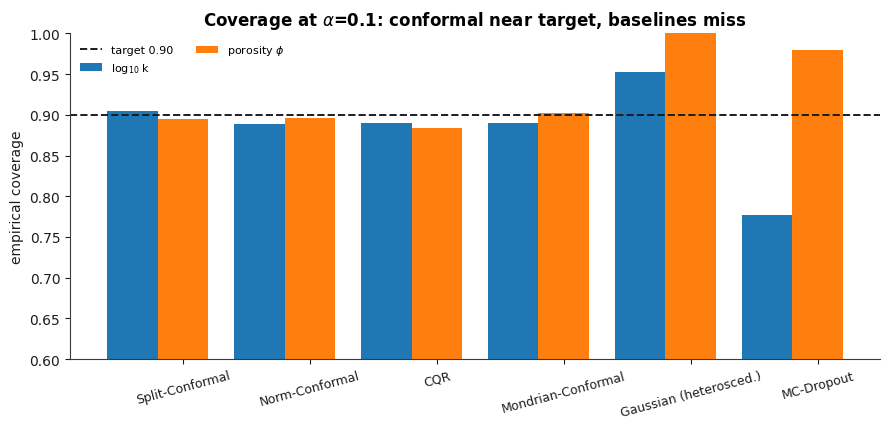

In [28]:
fig, ax = plt.subplots(figsize=(9,4.4))
piv = results.pivot_table(index="method", columns="property", values="coverage")
piv = piv.reindex(["Split-Conformal","Norm-Conformal","CQR","Mondrian-Conformal","Gaussian (heterosced.)","MC-Dropout"])
x = np.arange(len(piv)); w=0.8/len(cfg.properties)
for i,name in enumerate(cfg.properties):
    ax.bar(x+i*w, piv[name].values, w, label=PROPS_NICE.get(name,name))
ax.axhline(1-cfg.alpha, color=INK, ls="--", lw=1.4, label=f"target {1-cfg.alpha:.2f}")
ax.set_xticks(x+w); ax.set_xticklabels(piv.index, rotation=15, fontsize=9)
ax.set_ylabel("empirical coverage"); ax.set_ylim(0.6,1.0)
ax.set_title(f"Coverage at $\\alpha$={cfg.alpha}: conformal near target, baselines miss")
ax.legend(fontsize=8, frameon=False, ncol=2)
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout(); savefig(fig,"fig5_coverage_bars"); plt.show()


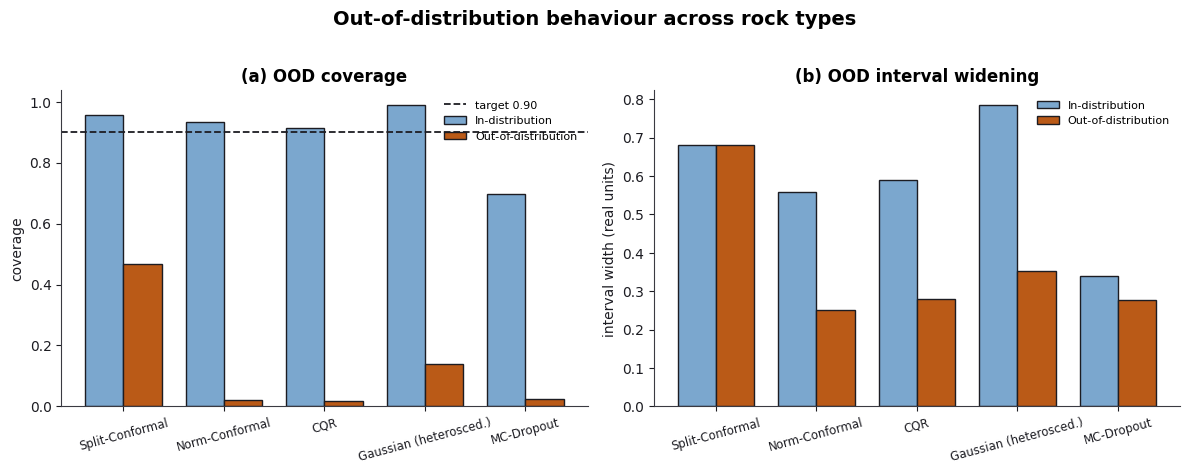

In [29]:
fig, (a1,a2) = plt.subplots(1,2, figsize=(12,4.6))
mo = res_shift[res_shift.property==cfg.ood_property]
methods = ["Split-Conformal","Norm-Conformal","CQR","Gaussian (heterosced.)","MC-Dropout"]
x=np.arange(len(methods)); w=0.38
for k,reg in enumerate(["In-distribution","Out-of-distribution"]):
    vals=[mo[(mo.method==m)&(mo.regime==reg)]["coverage"].values[0] for m in methods]
    a1.bar(x+k*w, vals, w, label=reg,
           color=["#7BA7CE","#BA5A17"][k], edgecolor=INK, linewidth=1)
a1.axhline(1-cfg.alpha,color=INK,ls="--",lw=1.3,label=f"target {1-cfg.alpha:.2f}")
a1.set_xticks(x+w/2); a1.set_xticklabels(methods,rotation=15,fontsize=8.5)
a1.set_ylabel("coverage"); a1.set_title("(a) OOD coverage")
a1.legend(fontsize=8,frameon=False); a1.spines[["top","right"]].set_visible(False)
for k,reg in enumerate(["In-distribution","Out-of-distribution"]):
    vals=[mo[(mo.method==m)&(mo.regime==reg)]["width"].values[0]*y_std[list(cfg.properties).index(cfg.ood_property)] for m in methods]
    a2.bar(x+k*w, vals, w, label=reg, color=["#7BA7CE","#BA5A17"][k], edgecolor=INK, linewidth=1)
a2.set_xticks(x+w/2); a2.set_xticklabels(methods,rotation=15,fontsize=8.5)
a2.set_ylabel("interval width (real units)"); a2.set_title("(b) OOD interval widening")
a2.legend(fontsize=8,frameon=False); a2.spines[["top","right"]].set_visible(False)
fig.suptitle("Out-of-distribution behaviour across rock types", y=1.02, fontsize=14, fontweight="bold")
fig.tight_layout(); savefig(fig,"fig6_ood"); plt.show()


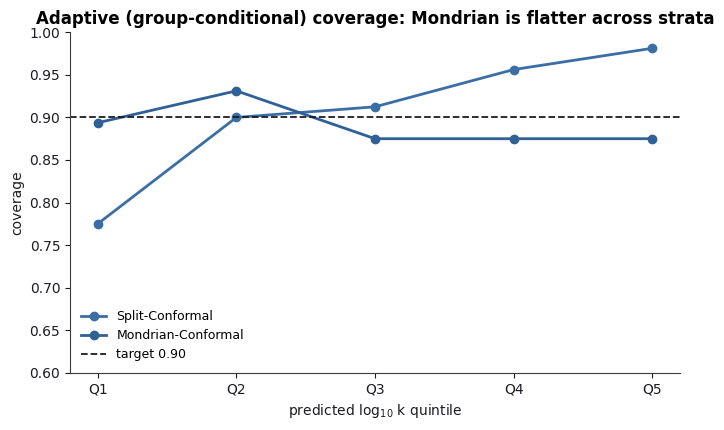

In [30]:
fig, ax = plt.subplots(figsize=(7,4.4))
j = list(cfg.properties).index(cfg.ood_property)
pred = te["mean"][:,j]; yj = te["y"][:,j]
edges = np.quantile(pred, np.linspace(0,1,6)); edges[-1]+=1e-6
binc = np.digitize(pred, edges[1:-1])
for mname,fn in [("Split-Conformal",split_conformal),("Mondrian-Conformal",None)]:
    if fn is split_conformal: lo,hi = split_conformal(cal,te,j,cfg.alpha)[:2]
    else: lo,hi = mondrian_conformal(cal,te,j,cfg.alpha)
    covs=[]
    for b in range(5):
        m=binc==b
        covs.append(coverage(yj[m],lo[m],hi[m]) if m.sum()>0 else np.nan)
    ax.plot(range(5), covs, marker="o", lw=2, color=C.get(mname), label=mname)
ax.axhline(1-cfg.alpha,color=INK,ls="--",lw=1.3,label=f"target {1-cfg.alpha:.2f}")
ax.set_xticks(range(5)); ax.set_xticklabels([f"Q{b+1}" for b in range(5)])
ax.set_xlabel(f"predicted {PROPS_NICE.get(cfg.ood_property)} quintile")
ax.set_ylabel("coverage"); ax.set_ylim(0.6,1.0)
ax.set_title("Adaptive (group-conditional) coverage: Mondrian is flatter across strata")
ax.legend(fontsize=9,frameon=False); ax.spines[["top","right"]].set_visible(False)
fig.tight_layout(); savefig(fig,"fig7_stratified"); plt.show()


## 11. Export results for the paper

Saves all metric tables as CSV and confirms the figures on disk. Download the
`conformal_out` folder (or mount Drive) to include these directly in the
manuscript.

In [31]:
import os
results.to_csv(f"{cfg.out_dir}/table_main_coverage.csv", index=False)
res_shift.to_csv(f"{cfg.out_dir}/table_ood.csv", index=False)
sweep.to_csv(f"{cfg.out_dir}/table_sweep.csv", index=False)

# summary table for the paper: coverage (marginal + worst-slice) and standardized
# width by method, averaged over properties. Standardized width is comparable
# across properties; |cov-target| measures calibration error.
summary = (results.groupby("method")
           .agg(mean_coverage=("coverage","mean"),
                mean_worst_slice=("worst_slice_cov","mean"),
                mean_width_std=("width_std","mean"))
           .reindex(["Split-Conformal","Norm-Conformal","CQR","Mondrian-Conformal",
                     "Gaussian (heterosced.)","MC-Dropout"]))
summary["|cov-target|"] = (summary["mean_coverage"]-(1-cfg.alpha)).abs()
summary["|worst-target|"] = (summary["mean_worst_slice"]-(1-cfg.alpha)).abs()
summary.to_csv(f"{cfg.out_dir}/table_summary.csv")
print(summary.round(3).to_string())

print("\nInterpretation guide for the paper:")
print(" - lower |cov-target|  -> better MARGINAL calibration")
print(" - lower |worst-target| -> better CONDITIONAL (local) calibration")
print(" - among methods that hit target, LOWER width_std is better (tighter, more useful)")

# mirror all outputs into the Drive run dir so results survive a disconnect
import shutil
drive_fig_dir = os.path.join(RUN_DIR, "figures_and_tables")
os.makedirs(drive_fig_dir, exist_ok=True)
for f in os.listdir(cfg.out_dir):
    shutil.copy(os.path.join(cfg.out_dir, f), os.path.join(drive_fig_dir, f))
print("\nFiles written to", cfg.out_dir)
print("Also mirrored to Drive:", drive_fig_dir)
for f in sorted(os.listdir(cfg.out_dir)): print("  ", f)


                        mean_coverage  mean_worst_slice  mean_width_std  |cov-target|  |worst-target|
method                                                                                               
Split-Conformal                 0.900             0.778           0.449         0.000           0.122
Norm-Conformal                  0.893             0.847           0.381         0.007           0.053
CQR                             0.887             0.803           0.409         0.013           0.097
Mondrian-Conformal              0.896             0.866           0.412         0.004           0.034
Gaussian (heterosced.)          0.976             0.966           0.687         0.076           0.066
MC-Dropout                      0.879             0.816           0.415         0.021           0.084

Interpretation guide for the paper:
 - lower |cov-target|  -> better MARGINAL calibration
 - lower |worst-target| -> better CONDITIONAL (local) calibration
 - among methods that hit t